
# 07 — Understanding BTL and CDM Through Interactions and Cyclic Preferences

**M.Tech Thesis — Learning Preference Models from Choice Data**

## Objective

The purpose of this notebook is to develop a mathematical and
computational understanding of the Context-Dependent Model (CDM),
with particular emphasis on its relationship to the
Bradley–Terry–Luce (BTL) model.

We begin with three alternatives, $A$, $B$, and $C$, and investigate
how pairwise interaction parameters determine choice probabilities.

Our central questions are:

1. What does the interaction parameter $u_{xz}$ represent?
2. How are CDM utilities constructed from the interaction matrix?
3. How do the pairwise choice probabilities under CDM compare
   with those under BTL?
4. Why can CDM represent cyclic preferences while BTL cannot?
5. How does the identifiability constraint affect the parameters?
6. Under what parameterization does CDM recover BTL?
7. What motivates a low-rank representation of the interaction matrix?

## Approach

We follow a progressive approach:

- **Mathematical derivation:** Establish the relevant equations.
- **Numerical illustration:** Work with three alternatives.
- **Computational verification:** Check mathematical identities
  using Python.
- **Visualization:** Present interaction matrices and choice
  probabilities using clearly labeled figures.
- **Interpretation:** Summarize what each result tells us
  about the models.

We use existing implementations from the project's `src/`
directory wherever appropriate.

## Scope

This notebook focuses on understanding the model structure
and its expressive capabilities.

Parameter estimation, maximum likelihood optimization,
large-scale synthetic experiments, and statistical recovery
analysis are outside the scope of this notebook.

## Expected Outcomes

By the end of this notebook, we should be able to:

- Interpret the entries of the CDM interaction matrix.
- Compute CDM choice probabilities for arbitrary choice sets.
- Explain the mathematical difference between BTL and CDM.
- Construct a cyclic preference example using CDM.
- Demonstrate the limitations of BTL in representing such cycles.
- Verify that BTL is contained within the CDM family.
- Identify the motivation for studying low-rank CDM.


In [1]:


# Cell 1 — Project setup and source-code inspection

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(
    (
        path
        for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "pyproject.toml").exists()
        and (path / "src").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root containing "
        "pyproject.toml and src/."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

SEED = 20260831
RNG = np.random.default_rng(SEED)

ITEMS = ("A", "B", "C")
N_ITEMS = len(ITEMS)

np.set_printoptions(precision=4, suppress=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Items: {ITEMS}")
print(f"Seed: {SEED}")

for module_dir in (
    PROJECT_ROOT / "src" / "bradley_terry",
    PROJECT_ROOT / "src" / "context_dependent_model",
):
    print(f"\n{module_dir.relative_to(PROJECT_ROOT)}/")

    if not module_dir.exists():
        print("  Directory not found")
        continue

    for file in sorted(module_dir.rglob("*.py")):
        if "__pycache__" not in file.parts:
            print(f"  {file.relative_to(PROJECT_ROOT)}")


Project root: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-
Items: ('A', 'B', 'C')
Seed: 20260831

src/bradley_terry/
  src/bradley_terry/__init__.py
  src/bradley_terry/choix_estimation.py
  src/bradley_terry/diagnostics.py
  src/bradley_terry/estimation.py
  src/bradley_terry/experiments.py
  src/bradley_terry/metrics.py
  src/bradley_terry/model.py
  src/bradley_terry/optimization.py
  src/bradley_terry/pytorch_optimization.py
  src/bradley_terry/sampling.py
  src/bradley_terry/simulation.py

src/context_dependent_model/
  src/context_dependent_model/__init__.py
  src/context_dependent_model/estimation.py
  src/context_dependent_model/experiments.py
  src/context_dependent_model/metrics.py
  src/context_dependent_model/model.py
  src/context_dependent_model/sampling.py
  src/context_dependent_model/simulation.py


In [2]:

# Cell 2 — Inspect available model functions and signatures

import ast

SOURCE_FILES = [
    PROJECT_ROOT / "src/bradley_terry/model.py",
    PROJECT_ROOT / "src/context_dependent_model/model.py",
]

for file_path in SOURCE_FILES:
    print(f"\n{'=' * 65}")
    print(file_path.relative_to(PROJECT_ROOT))
    print("=" * 65)

    if not file_path.exists():
        print("File not found.")
        continue

    tree = ast.parse(file_path.read_text(encoding="utf-8"))

    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            print(f"\nFunction: {node.name}")
            print(f"Signature: {ast.unparse(node.args)}")

        elif isinstance(node, ast.ClassDef):
            print(f"\nClass: {node.name}")

            for method in node.body:
                if isinstance(method, (ast.FunctionDef, ast.AsyncFunctionDef)):
                    if not method.name.startswith("_"):
                        print(f"  Method: {method.name}")
                        print(f"  Signature: {ast.unparse(method.args)}")



src/bradley_terry/model.py

Function: _as_parameter_array
Signature: parameters

Function: _as_comparison_array
Signature: comparisons, number_of_items

Function: sigmoid
Signature: value

Function: center_parameters
Signature: parameters

Function: bradley_terry_probability
Signature: item_i, item_j, parameters

Function: average_negative_log_likelihood
Signature: parameters, comparisons

Function: average_negative_log_likelihood_gradient
Signature: parameters, comparisons

src/context_dependent_model/model.py

Function: center_cdm_parameters
Signature: interaction_matrix: torch.Tensor

Function: cdm_choice_utilities
Signature: interaction_matrix: torch.Tensor, choice_sets: torch.Tensor, choice_mask: torch.Tensor | None=None

Function: cdm_choice_probabilities
Signature: interaction_matrix: torch.Tensor, choice_sets: torch.Tensor, choice_mask: torch.Tensor | None=None

Function: average_cdm_negative_log_likelihood
Signature: interaction_matrix: torch.Tensor, choice_sets: torch.Tensor


---

## Part 1 — Reparameterization and the Interaction Matrix

### 1.1 From the original utility to the reparameterized utility

Consider a choice set $C$ and an alternative $x\in C$.

The second-order utility is defined as

$$
v(x\mid C)
=
v(x)
+
\sum_{z\in C\setminus\{x\}}v(x\mid\{z\}).
$$

We introduce the interaction parameter

$$
\boxed{
u_{xz}=v(x\mid\{z\})-v(z),\qquad x\neq z.
}
$$

Rearranging,

$$
v(x\mid\{z\})=u_{xz}+v(z).
$$

Substituting this expression into the original utility,

$$
\begin{aligned}
v(x\mid C)
&=v(x)+\sum_{z\in C\setminus\{x\}}v(x\mid\{z\})\\[6pt]
&=v(x)+\sum_{z\in C\setminus\{x\}}u_{xz}
+\sum_{z\in C\setminus\{x\}}v(z)\\[6pt]
&=\underbrace{
v(x)+\sum_{z\in C\setminus\{x\}}v(z)
}_{\displaystyle\sum_{z\in C}v(z)}
+\sum_{z\in C\setminus\{x\}}u_{xz}\\[6pt]
&=\sum_{z\in C}v(z)
+\sum_{z\in C\setminus\{x\}}u_{xz}.
\end{aligned}
$$

The first term is identical for every alternative in the
same choice set. Therefore, it cancels from the softmax
choice probabilities.

We obtain the equivalent utility representation

$$
\boxed{
\widetilde{u}(x\mid C)
=
\sum_{z\in C\setminus\{x\}}u_{xz}.
}
$$

The original and reparameterized utilities need not be
numerically equal, but they produce identical choice
probabilities.

### Interpretation

The parameter $u_{xz}$ represents the contribution
associated with the presence of alternative $z$ to the
reparameterized utility of alternative $x$.

- $x$ is the **target alternative**.
- $z$ is the **context alternative**.
- $u_{xz}$ and $u_{zx}$ are distinct parameters.

The interpretation of an individual interaction parameter
must be understood relative to the model's parameterization
and identifiability convention.



### 1.2 Constructing the interaction matrix

For three alternatives,

$$
C=\{A,B,C\},
$$

the interaction matrix is

$$
U=
\begin{bmatrix}
0 & u_{AB} & u_{AC}\\
u_{BA} & 0 & u_{BC}\\
u_{CA} & u_{CB} & 0
\end{bmatrix}.
$$

Rows represent target alternatives, while columns represent
context alternatives.

The diagonal is zero because an alternative does not
interact with itself in the CDM utility formulation.

For the choice set $\{A,B,C\}$,

$$
\begin{aligned}
\widetilde{u}(A\mid\{A,B,C\}) &= u_{AB}+u_{AC},\\
\widetilde{u}(B\mid\{A,B,C\}) &= u_{BA}+u_{BC},\\
\widetilde{u}(C\mid\{A,B,C\}) &= u_{CA}+u_{CB}.
\end{aligned}
$$

For the smaller choice set $\{A,B\}$,

$$
\widetilde{u}(A\mid\{A,B\})=u_{AB},
\qquad
\widetilde{u}(B\mid\{A,B\})=u_{BA}.
$$

**Key observation:** The utility of an alternative depends
on which other alternatives are present in the choice set.


In [3]:

# Cell 5 — Construct a three-item CDM interaction matrix

import torch

from context_dependent_model.model import (
    center_cdm_parameters,
    cdm_choice_utilities,
    cdm_choice_probabilities,
)

DTYPE = torch.float64

# Rows: target items; columns: context items.
U_raw = torch.tensor(
    [
        [0.0,  1.0,  0.5],   # Target A
        [-0.5, 0.0,  0.8],   # Target B
        [0.2, -0.4,  0.0],   # Target C
    ],
    dtype=DTYPE,
)

# Apply the existing CDM centering convention.
U = center_cdm_parameters(U_raw)

interaction_table = pd.DataFrame(
    U.detach().numpy(),
    index=ITEMS,
    columns=ITEMS,
)

print("CDM interaction matrix:")
display(interaction_table.round(4))

print(f"Sum of interaction parameters: {U.sum().item():.8f}")
print(f"Diagonal entries: {torch.diag(U).tolist()}")

assert torch.allclose(
    torch.diag(U),
    torch.zeros(N_ITEMS, dtype=DTYPE),
)

assert torch.isclose(
    U.sum(),
    torch.tensor(0.0, dtype=DTYPE),
    atol=1e-10,
)


CDM interaction matrix:


,A,B,C
A,-0.0000,0.7333,0.2333
B,-0.7667,-0.0000,0.5333
C,-0.0667,-0.6667,-0.0000


Sum of interaction parameters: 0.00000000
Diagonal entries: [-0.0, -0.0, -0.0]


In [4]:

# Cell 6 — Verify CDM utilities for different choice sets

# Each row contains one choice set.
choice_sets = torch.tensor(
    [
        [0, 1, 2],  # {A, B, C}
        [0, 1, 0],  # {A, B}; final entry is padding
    ],
    dtype=torch.long,
)

choice_mask = torch.tensor(
    [
        [True, True, True],
        [True, True, False],
    ],
    dtype=torch.bool,
)

utilities = cdm_choice_utilities(
    interaction_matrix=U,
    choice_sets=choice_sets,
    choice_mask=choice_mask,
)

print("Utilities returned by src/context_dependent_model/model.py:")
print(utilities)

# Verify the three-item choice set manually.
expected_abc = torch.tensor(
    [
        U[0, 1] + U[0, 2],
        U[1, 0] + U[1, 2],
        U[2, 0] + U[2, 1],
    ],
    dtype=DTYPE,
)

assert torch.allclose(utilities[0], expected_abc)

# Verify the two-item choice set.
assert torch.allclose(
    utilities[1, :2],
    torch.stack([U[0, 1], U[1, 0]]),
)

print("\nBoth utility calculations match the manual equations.")


Utilities returned by src/context_dependent_model/model.py:
tensor([[ 0.9667, -0.2333, -0.7333],
        [ 0.7333, -0.7667,    -inf]], dtype=torch.float64)

Both utility calculations match the manual equations.



---

## Part 2 — Pairwise Choice Probabilities Under CDM

### 2.1 From interaction parameters to choice probabilities

Consider two alternatives, $A$ and $B$, with the choice set

$$
C=\{A,B\}.
$$

Under the reparameterized CDM, their utilities are

$$
\widetilde{u}(A\mid C)=u_{AB},
\qquad
\widetilde{u}(B\mid C)=u_{BA}.
$$

Using the softmax choice rule,

$$
P(A\mid\{A,B\})
=
\frac{\exp(u_{AB})}
{\exp(u_{AB})+\exp(u_{BA})}.
$$

Dividing the numerator and denominator by $\exp(u_{AB})$,

$$
P(A\mid\{A,B\})
=
\frac{1}{1+\exp(u_{BA}-u_{AB})}.
$$

Recall that the sigmoid function is

$$
\sigma(t)=\frac{1}{1+\exp(-t)}.
$$

Therefore,

$$
\boxed{
P(A\mid\{A,B\})=\sigma(u_{AB}-u_{BA}).
}
$$

Similarly,

$$
\boxed{
P(B\mid\{B,C\})=\sigma(u_{BC}-u_{CB})
}
$$

and

$$
\boxed{
P(C\mid\{C,A\})=\sigma(u_{CA}-u_{AC}).
}
$$

### Key observation

For a pairwise choice, the probability depends on the
**difference between two directed interaction parameters**.

For example, $u_{AB}$ and $u_{BA}$ need not be equal.

A positive value of $u_{AB}-u_{BA}$ implies

$$
P(A\mid\{A,B\})>0.5.
$$

This formulation will allow us to compare CDM with BTL
and investigate cyclic preferences.


In [5]:

# Cell 8 — Verify pairwise CDM probabilities using softmax and sigmoid

from bradley_terry.model import sigmoid

PAIR_INDICES = [(0, 1), (1, 2), (2, 0)]
PAIR_NAMES = ["A vs B", "B vs C", "C vs A"]

pair_choice_sets = torch.tensor(
    PAIR_INDICES,
    dtype=torch.long,
)

# Probabilities computed by the existing CDM implementation.
pair_probabilities = cdm_choice_probabilities(
    interaction_matrix=U,
    choice_sets=pair_choice_sets,
)

rows = []

for pair_name, (i, j), probabilities in zip(
    PAIR_NAMES, PAIR_INDICES, pair_probabilities
):
    interaction_difference = (U[i, j] - U[j, i]).item()

    probability_sigmoid = float(
        np.asarray(sigmoid(interaction_difference))
    )

    probability_cdm = probabilities[0].item()

    rows.append(
        {
            "Pair": pair_name,
            "Interaction difference": interaction_difference,
            "Sigmoid probability": probability_sigmoid,
            "CDM probability": probability_cdm,
            "Absolute difference": abs(
                probability_sigmoid - probability_cdm
            ),
        }
    )

pairwise_results = pd.DataFrame(rows)

display(pairwise_results.round(6))

assert np.allclose(
    pairwise_results["Sigmoid probability"],
    pairwise_results["CDM probability"],
    atol=1e-10,
)

assert torch.allclose(
    pair_probabilities.sum(dim=1),
    torch.ones(3, dtype=DTYPE),
)

print("Verified: sigmoid and CDM softmax probabilities agree.")


,Pair,Interaction difference,Sigmoid probability,CDM probability,Absolute difference
0,A vs B,1.5,0.817574,0.817574,0.0
1,B vs C,1.2,0.768525,0.768525,0.0
2,C vs A,-0.3,0.425557,0.425557,0.0


Verified: sigmoid and CDM softmax probabilities agree.


In [6]:

# Cell 8 — Verify pairwise CDM probabilities using softmax and sigmoid

from bradley_terry.model import sigmoid

PAIR_INDICES = [(0, 1), (1, 2), (2, 0)]
PAIR_NAMES = ["A vs B", "B vs C", "C vs A"]

pair_choice_sets = torch.tensor(
    PAIR_INDICES,
    dtype=torch.long,
)

# Probabilities computed by the existing CDM implementation.
pair_probabilities = cdm_choice_probabilities(
    interaction_matrix=U,
    choice_sets=pair_choice_sets,
)

rows = []

for pair_name, (i, j), probabilities in zip(
    PAIR_NAMES, PAIR_INDICES, pair_probabilities
):
    interaction_difference = (U[i, j] - U[j, i]).item()

    probability_sigmoid = float(
        np.asarray(sigmoid(interaction_difference))
    )

    probability_cdm = probabilities[0].item()

    rows.append(
        {
            "Pair": pair_name,
            "Interaction difference": interaction_difference,
            "Sigmoid probability": probability_sigmoid,
            "CDM probability": probability_cdm,
            "Absolute difference": abs(
                probability_sigmoid - probability_cdm
            ),
        }
    )

pairwise_results = pd.DataFrame(rows)

display(pairwise_results.round(6))

assert np.allclose(
    pairwise_results["Sigmoid probability"],
    pairwise_results["CDM probability"],
    atol=1e-10,
)

assert torch.allclose(
    pair_probabilities.sum(dim=1),
    torch.ones(3, dtype=DTYPE),
)

print("Verified: sigmoid and CDM softmax probabilities agree.")


,Pair,Interaction difference,Sigmoid probability,CDM probability,Absolute difference
0,A vs B,1.5,0.817574,0.817574,0.0
1,B vs C,1.2,0.768525,0.768525,0.0
2,C vs A,-0.3,0.425557,0.425557,0.0


Verified: sigmoid and CDM softmax probabilities agree.


In [8]:

# Cell 10 — Compare BTL and CDM pairwise choice probabilities

from bradley_terry.model import (
    bradley_terry_probability,
    center_parameters,
)

theta = center_parameters(
    np.array([1.0, 0.0, -1.0], dtype=np.float64)
)

comparison_rows = []

for pair_name, (i, j), cdm_probs in zip(
    PAIR_NAMES, PAIR_INDICES, pair_probabilities
):
    p_btl = float(
        bradley_terry_probability(i, j, theta)
    )

    p_cdm = float(cdm_probs[0].item())

    comparison_rows.append(
        {
            "Pair": pair_name,
            "BTL probability": p_btl,
            "CDM probability": p_cdm,
            "Difference (CDM - BTL)": p_cdm - p_btl,
        }
    )

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df.round(6))

# Verify the BTL pairwise log-odds constraint.
btl_log_odds = [
    theta[i] - theta[j]
    for i, j in PAIR_INDICES
]

assert np.isclose(sum(btl_log_odds), 0.0)

print("BTL pairwise log-odds:", btl_log_odds)
print("Sum of BTL pairwise log-odds:", sum(btl_log_odds))


,Pair,BTL probability,CDM probability,Difference (CDM - BTL)
0,A vs B,0.731059,0.817574,0.086516
1,B vs C,0.731059,0.768525,0.037466
2,C vs A,0.119203,0.425557,0.306355


BTL pairwise log-odds: [np.float64(1.0), np.float64(1.0), np.float64(-2.0)]
Sum of BTL pairwise log-odds: 0.0


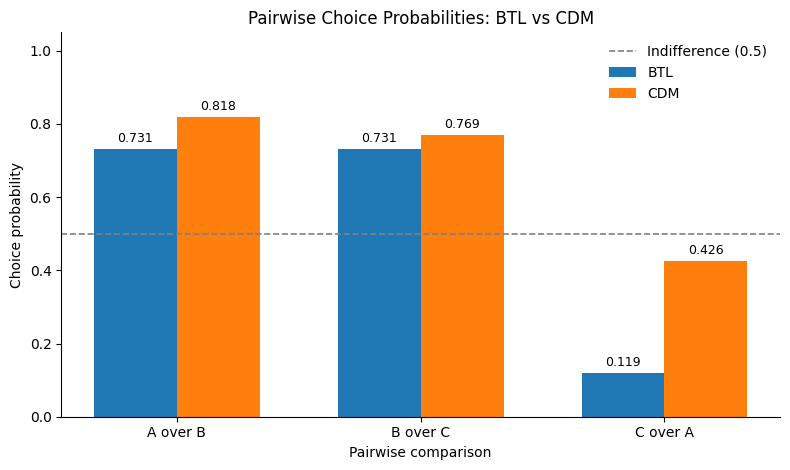

Figure saved to: docs/thesis/images/experiments/context_dependent_model/foundations/btl_vs_cdm_pairwise_probabilities.png


In [9]:

# Cell 11 — Visualize BTL and CDM pairwise probabilities

FIGURE_DIR = (
    PROJECT_ROOT
    / "docs/thesis/images/experiments"
    / "context_dependent_model/foundations"
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

labels = ["A over B", "B over C", "C over A"]
x_positions = np.arange(len(labels))
bar_width = 0.34

fig, ax = plt.subplots(figsize=(8, 4.8))

bars_btl = ax.bar(
    x_positions - bar_width / 2,
    comparison_df["BTL probability"],
    bar_width,
    label="BTL",
)

bars_cdm = ax.bar(
    x_positions + bar_width / 2,
    comparison_df["CDM probability"],
    bar_width,
    label="CDM",
)

ax.axhline(
    0.5,
    linestyle="--",
    linewidth=1.2,
    color="gray",
    label="Indifference (0.5)",
)

ax.set_xticks(x_positions, labels)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Choice probability")
ax.set_xlabel("Pairwise comparison")
ax.set_title("Pairwise Choice Probabilities: BTL vs CDM")
ax.legend(frameon=False)

for bars in (bars_btl, bars_cdm):
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

figure_path = FIGURE_DIR / "btl_vs_cdm_pairwise_probabilities.png"

fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {figure_path.relative_to(PROJECT_ROOT)}")
